In [1]:
%pip install numpy matplotlib pylatexenc "qiskit>=2.0" "qiskit-aer>=0.17" --quiet

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import math
import random
import numpy as np
import sys
from IPython.display import display
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_distribution

In [3]:
class groverSearch:
  def initialize(self): # O(N)
    # quantum state = 1/root_N (summation_(N) |i>|0>|->)

    print("\nTotal qubits: ", self.total_qubits)
    qc = QuantumCircuit(self.total_qubits)

    print("Index qubits: ", self.index_q)

    # handling dataset of arbitrary size
    amplitudes = np.zeros(2**self.n, dtype=complex) # O(N)

    for i in range(2**self.n):  # O(N)
        amplitudes[i] = 1 / np.sqrt(2**self.n)

    state = Statevector(amplitudes)

    qc.initialize(state, range(self.n))
    qc.x(self.ancilla) # |0> --> |1>
    qc.h(self.ancilla) # |1> --> |->
    qc.barrier()

    return qc

  def database_lookup(self, qc):  # O(N.(logN+d))
    # database values --encode--> quantum gates
    # U_d |i>|0>|-> = |i>|d>|->

    # FUTURE WORK: Improve this part, replace with qRAM ?
    # or maybe separate from grover search iterations as a preprocessing/state preparation step
    for index, value in enumerate(dataset): # O(N.(logN+d))
        zero_controls = []

        for bit in range(self.n):
            if ((index >> bit) & 1) == 0: # detects which index bits are 0
                qc.x(self.index_q[bit]) # 0 --> 1
                zero_controls.append(self.index_q[bit]) # to later convert 1 --> 0

        for bit in range(self.d):
            if ((value >> bit) & 1) == 1:
                qc.mcx(self.index_q, self.data_q[bit])  # data_q[bit] = 1

        for q in zero_controls:
            qc.x(q) # convert the previously converted 1 --> 0 (original)

    return qc

  def mark_target(self, qc):  # O(d)
    # 1/root_N summation_(N) ( |i>|d>|-> ) --mark_target -->
    # 1/root_N ( -summation_(M) |i>|T>|-> + summation_(N-M) ( |i>|d>|-> ) )

    zero_controls = []

    for bit in range(self.d):
      if ((target >> bit) & 1) == 0:
          qc.x(self.data_q[bit])
          zero_controls.append(self.data_q[bit])

    qc.mcx(self.data_q, self.ancilla) # |-> --> -|-> (phase kickback for target)

    for q in zero_controls:
      qc.x(q)

    return qc

  def oracle(self): # O(N.(logN+d))
    qc = QuantumCircuit(self.total_qubits)

    self.database_lookup(qc) # O(N.(logN+d))
    qc.barrier()

    self.mark_target(qc) # O(d)
    qc.barrier()

    self.database_lookup(qc) # O(N.(logN+d))
    qc.barrier()

    return qc

  def diffuser(self): # O(1)
    # D = 2∣s⟩⟨s∣ − I
    # D∣ψ⟩ = ∑_i​ (2.mean − a_i​)∣i⟩

    qc = QuantumCircuit(self.n)

    qc.h(self.index_q) # makes the amplitude of |00...0> twice the mean of all the amplitudes
    qc.x(self.index_q) # |00...0> --> |11...1>

    if self.n == 1:  # only one qubit
        qc.z(0) # change the phase of the one qubit

    else:
        # H.MCX.H = MCZ (controlled phase flip)
        qc.h(self.n - 1) # qubit[n-1] is last index qubit
        qc.mcx(list(range(self.n - 1)), self.n - 1) # |11...1> --> - |11...1>
        qc.h(self.n - 1)

    qc.x(self.index_q) # |11...1> --> |00...0> has -2.mean amplitude
    qc.h(self.index_q) # inversion about mean: every amplitude = 2.mean - amplitude

    qc.barrier()

    return qc

  def visualize(self, qc, text):
    no_of_locators_on_chart = 10    # shows maximum of 10 locators on the x-axis of the chart (decreases overcrowding)

    state = Statevector.from_instruction(qc)
    # display(plot_state_qsphere(state))
    probs_dict = state.probabilities_dict(qargs=self.index_q)
    probs_dict = {int(k, 2): v for k, v in probs_dict.items()}  # convert binary index to decimal

    print(f"{text}: ", probs_dict)
    plot = plot_distribution(probs_dict, bar_labels=False)
    plot.axes[0].xaxis.set_major_locator(plt.MaxNLocator(no_of_locators_on_chart))
    display(plot)

  def run(self, dataset, target, no_of_shots=10):
    self.N = len(dataset)
    self.n = math.ceil(math.log2(self.N))

    # PROBLEM: finding max O(N) and as d increases so does the number of qubits and the complexity of the circuit.
    # it can be 32 bit or 64 integer depending on the system and hence would require as many qubits
    self.d = math.ceil(math.log2(max(dataset) + 1))

    self.index_q = list(range(self.n))
    self.data_q = list(range(self.n, self.n + self.d))
    self.ancilla = self.n + self.d
    self.total_qubits = self.n + self.d + 1

    print("N = ", self.N)
    print("n = ", self.n)
    print("Index qubits = ", self.index_q)
    print("Data qubits = ", self.data_q)
    print("Ancilla = ", self.ancilla)
    print("Total no of qubits = ", self.total_qubits)

    theta = math.asin(math.sqrt(M / self.N)) + sys.float_info.epsilon
    no_of_iter = max(1, round(((math.pi / 4) * math.sqrt(N / M)) - 0.5))

    print(f"\nTheta: {theta}")
    print(f"Total no of iterations: {no_of_iter}")

    index_qubits = QuantumRegister(self.n, name="index")
    data_qubits = QuantumRegister(self.d, name="data")
    ancilla_qubit = QuantumRegister(1, name="ancilla")
    classical_register = ClassicalRegister(self.n, name="index_result")
    qc = QuantumCircuit(index_qubits, data_qubits, ancilla_qubit, classical_register)

    init = self.initialize() # O(N)
    qc.compose(init,inplace=True)
    self.visualize(qc, "Initial state")

    for iteration in range(no_of_iter):     # O(root_N * (N.(logN+d))) ≈ O(N^(3/2).logN)

        print(f"\nGROVER ITERATION {iteration+1}")

        print("\nORACLE")
        oracle_circuit = self.oracle()   # O(N.(logN+d))
        qc.compose(oracle_circuit, qubits=self.index_q + self.data_q + [self.ancilla],inplace=True)
        state_oracle = Statevector.from_instruction(qc)
        probs_dict = state_oracle.probabilities_dict(qargs=self.index_q)
        probs_dict = {int(k, 2): v for k, v in probs_dict.items()}
        self.visualize(qc, "Oracle output")

        print("\nDIFFUSER")
        diffuser_circuit = self.diffuser()   # O(1)
        qc.compose(diffuser_circuit, qubits=self.index_q, inplace=True)
        self.visualize(qc, "Diffuser output")

    print("\nFINAL MEASUREMENT")

    self.qc = qc.copy()
    self.qc.measure(self.index_q, range(self.n))

    simulator = AerSimulator()
    compiled = transpile(self.qc, simulator)
    result = simulator.run(compiled, shots=no_of_shots).result()
    counts = result.get_counts()

    print(f"\nIndex measurement results for ({no_of_shots}) shots:")
    print(counts)

  def draw_circuit(self):
    display(self.qc.draw("mpl"))
    
  def analysis(self):
    print("REGISTER ANALYSIS")

    print("Dataset size   (N):", self.N)
    print("Index qubits   (n):", len(self.index_q))
    print("Data qubits    (d):", len(self.data_q))
    print("Ancilla           :", 1)
    print("Classical bits (n):", len(self.index_q))

    print("\nCIRCUIT ANALYSIS")

    print("Total qubits                                    :", self.qc.num_qubits)
    print("Circuit width (quantum bits + classical bits)   :", self.qc.width())
    print("Circuit size (total number of operations/gates) :", self.qc.size())
    print("Circuit depth/layers                            :", self.qc.depth())

    print("\nOPERATION COUNT")
    print(self.qc.count_ops())

In [4]:
N = 10
max_data_element = 10000

In [5]:
dataset = [random.randint(0,max_data_element) for _ in range(N)]
print("Dataset: ", dataset)

Dataset:  [6534, 3858, 3376, 9296, 9973, 8308, 6482, 7709, 5833, 4749]


In [6]:
target = random.choice(dataset)
target

3858

In [7]:
# actual answer through classical search
target_indices = [
    i for i, value in enumerate(dataset)
    if value == target
]
M = len(target_indices)
target_indices

[1]

N =  10
n =  4
Index qubits =  [0, 1, 2, 3]
Data qubits =  [4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
Ancilla =  18
Total no of qubits =  19

Theta: 0.3217505543966424
Total no of iterations: 2

Total qubits:  19
Index qubits:  [0, 1, 2, 3]
Initial state:  {0: np.float64(0.062499999999999986), 1: np.float64(0.062499999999999986), 2: np.float64(0.062499999999999986), 3: np.float64(0.062499999999999986), 4: np.float64(0.062499999999999986), 5: np.float64(0.062499999999999986), 6: np.float64(0.062499999999999986), 7: np.float64(0.062499999999999986), 8: np.float64(0.062499999999999986), 9: np.float64(0.062499999999999986), 10: np.float64(0.062499999999999986), 11: np.float64(0.062499999999999986), 12: np.float64(0.062499999999999986), 13: np.float64(0.062499999999999986), 14: np.float64(0.062499999999999986), 15: np.float64(0.062499999999999986)}


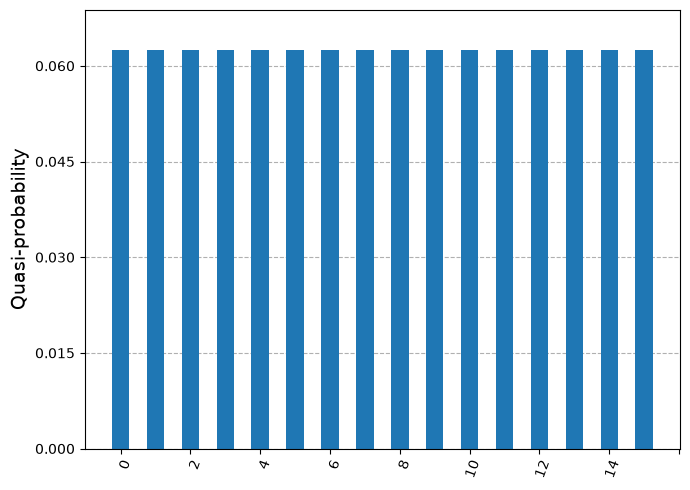


GROVER ITERATION 1

ORACLE


In [ ]:
GS = groverSearch()
GS.run(dataset, target)

In [ ]:
GS.draw_circuit()

In [ ]:
GS.analysis()